## **1. Project Introduction**

**Project Title:** Online Retail Sales and Customer Analytics

**Business objective:** Analyze online retail transactions to understand sales trends, product performance, customer purchasing behavior, and geographical sales patterns, then use these findings to recommend improvements to business performance.

### **2. Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [2]:
file_name = "Online Retail.xlsx"

df = pd.read_excel(
    file_name,
    dtype={
        "InvoiceNo": str,
        "StockCode": str
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### **3. Dataset Inspection**

In [3]:
print("First five rows:\n")
df.head()

First five rows:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541909
Columns: 8


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_values.sort_values(
    "Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


### **4. Data Quality Issues**

In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nCancellation invoices:")
print(df["InvoiceNo"].str.startswith("C", na=False).sum())

print("\nNon-positive quantities:")
print((df["Quantity"] <= 0).sum())

print("\nNon-positive unit prices:")
print((df["UnitPrice"] <= 0).sum())

print("\nDate range:")
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows:
5268

Cancellation invoices:
9288

Non-positive quantities:
10624

Non-positive unit prices:
2517

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


### **5. Data Cleaning**

In [10]:
raw_df = df.copy()

clean_df = raw_df.drop_duplicates().copy()

clean_df = clean_df.dropna(
    subset=[
        "InvoiceNo",
        "StockCode",
        "InvoiceDate",
        "Quantity",
        "UnitPrice",
        "Country"
    ]
)

# Exclude cancellation invoices
clean_df = clean_df[
    ~clean_df["InvoiceNo"].str.startswith("C", na=False)
].copy()

# Retain positive quantities and prices
clean_df = clean_df[
    (clean_df["Quantity"] > 0) & (clean_df["UnitPrice"] > 0)
].copy()

# Clean product descriptions
clean_df["Description"] = clean_df["Description"].astype("string").str.strip()

# Create sales revenue
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Create useful date columns
clean_df["Year"] = clean_df["InvoiceDate"].dt.year
clean_df["Month"] = clean_df["InvoiceDate"].dt.month
clean_df["MonthYear"] = (
    clean_df["InvoiceDate"].dt.to_period("M").astype(str)
)

print("Original rows:", len(raw_df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(raw_df) - len(clean_df))
print("Remaining duplicates:", clean_df.duplicated().sum())
print("Remaining missing values:")
print(clean_df.isnull().sum())

Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031
Remaining duplicates: 0
Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Year                0
Month               0
MonthYear           0
dtype: int64


In [11]:
clean_df.to_csv(
    "cleaned_online_retail.csv",
    index=False
)

files.download("cleaned_online_retail.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **6. Exploratory Data Analysis**

In [15]:
print("Total Sales (£): ", round(clean_df["Revenue"].sum(), 2))
print("Total quantity sold: ", clean_df["Quantity"].sum())
print("Unique invoices: ", clean_df["InvoiceNo"].nunique())
print("Unique products: ", clean_df["StockCode"].nunique())
print("Unique customers: ", clean_df["CustomerID"].nunique())
print("Unique countries: ", clean_df["Country"].nunique())

clean_df[["Quantity", "UnitPrice", "Revenue"]].describe()

Total Sales (£):  10642110.8
Total quantity sold:  5572420
Unique invoices:  19960
Unique products:  3922
Unique customers:  4338
Unique countries:  38


,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [16]:
monthly_sales = (
    clean_df.groupby("MonthYear")["Revenue"]
    .sum()
    .sort_index()
)

monthly_sales

,Revenue
MonthYear,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


In [20]:
top_products = (
    clean_df.groupby("Description")
    .agg(
        Total_Sales=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

top_products

,Total_Sales,Units_Sold
Description,,
DOTCOM POSTAGE,206248.77,706
REGENCY CAKESTAND 3 TIER,174156.54,13851
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872
PARTY BUNTING,99445.23,18283
JUMBO BAG RED RETROSPOT,94159.81,48371
MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
POSTAGE,78101.88,3150
Manual,77752.82,6985


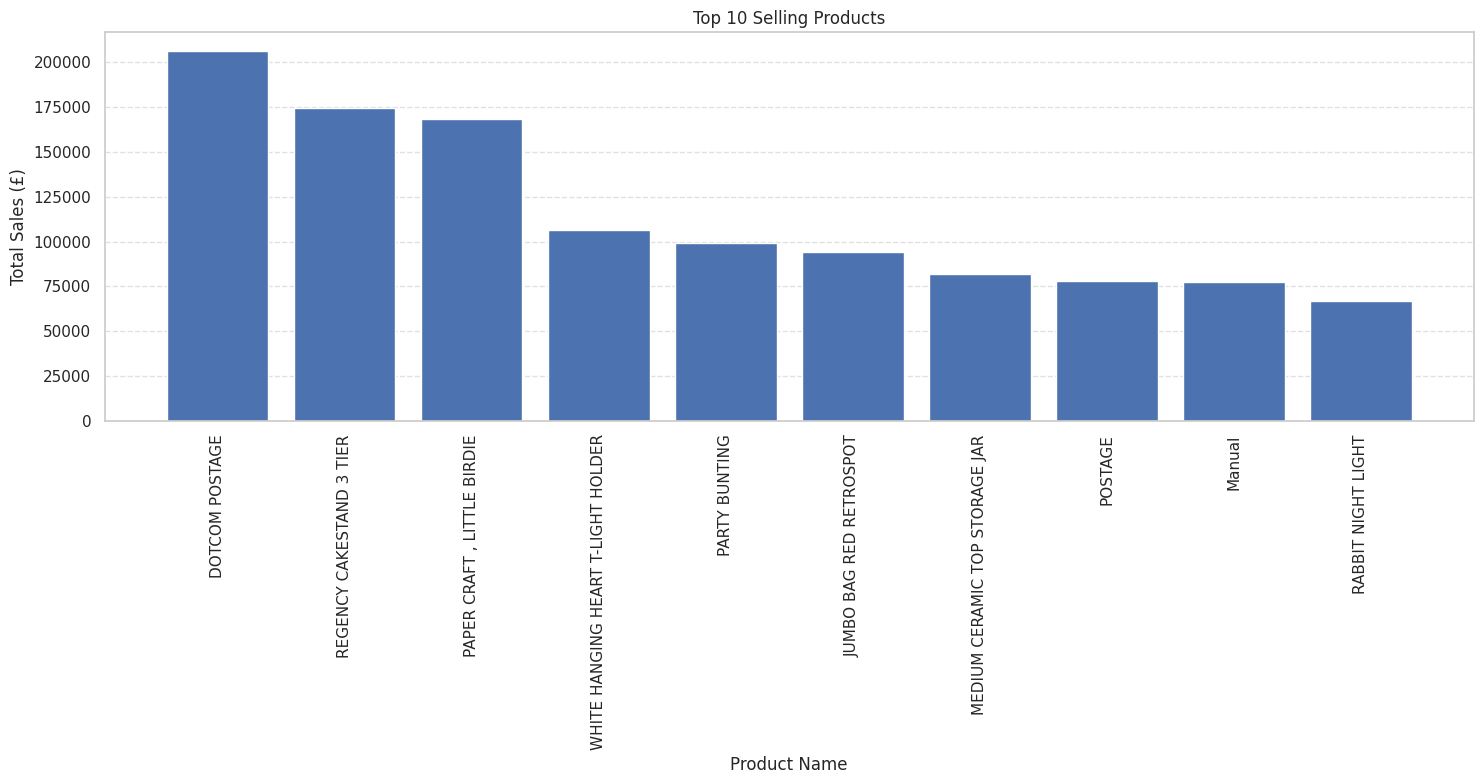

In [34]:
plt.figure(figsize=(15, 8))

plt.bar(top_products.index, top_products["Total_Sales"])
plt.xlabel("Product Name")
plt.ylabel("Total Sales (£)")
plt.title("Top 10 Selling Products")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.grid(axis="x", visible=None)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [35]:
country_sales = (
    clean_df.groupby("Country")
    .agg(
        Total_Sales=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

country_sales.head(10)

,Total_Sales,Total_Orders
Country,,
United Kingdom,9001744.094,18019
Netherlands,285446.340,94
EIRE,283140.520,288
Germany,228678.400,457
France,209625.370,392
Australia,138453.810,57
Spain,61558.560,90
Switzerland,57067.600,54
Belgium,41196.340,98


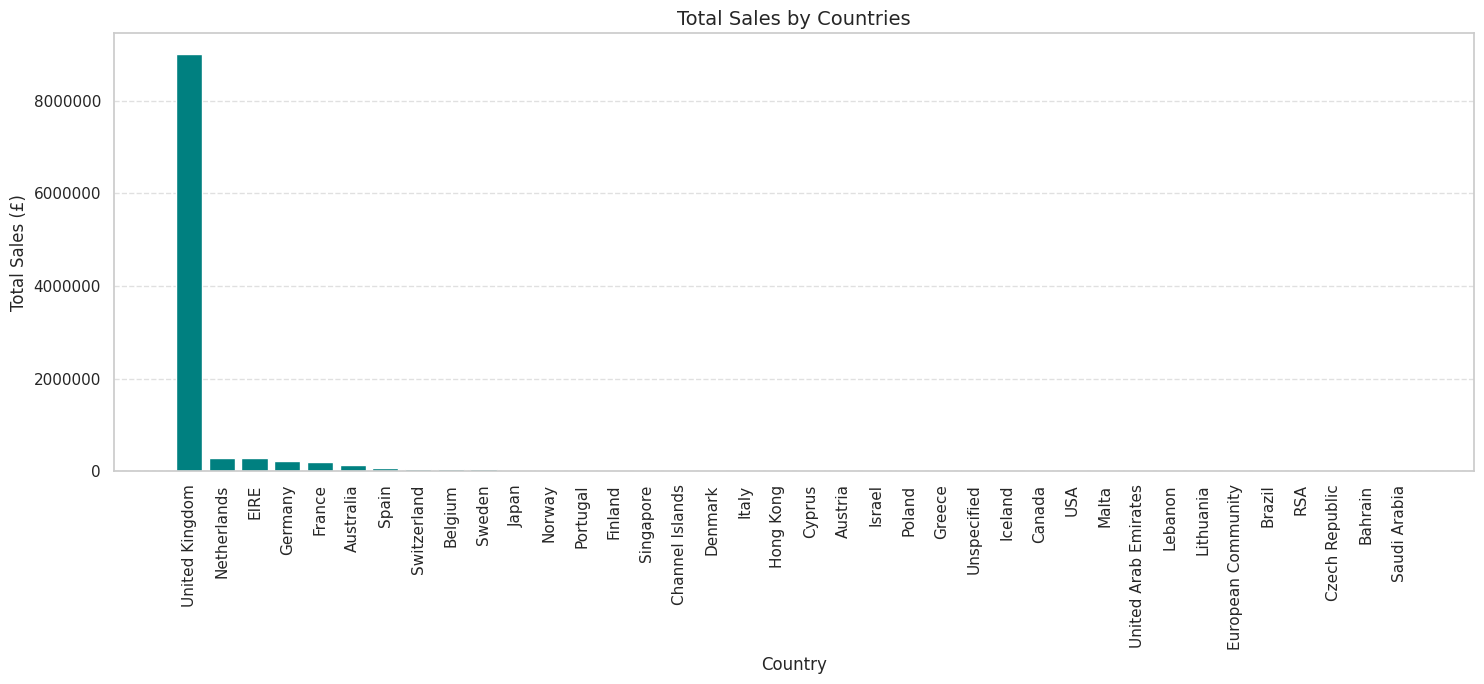

In [45]:
from matplotlib import lines
plt.figure(figsize=(15, 7))
plt.bar(country_sales.index, country_sales.Total_Sales, color='teal')
plt.title("Total Sales by Countries", fontsize=14)
plt.xlabel("Country")
plt.ylabel("Total Sales (£)")
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.grid(axis="x", visible=None)
plt.tight_layout()
plt.show()

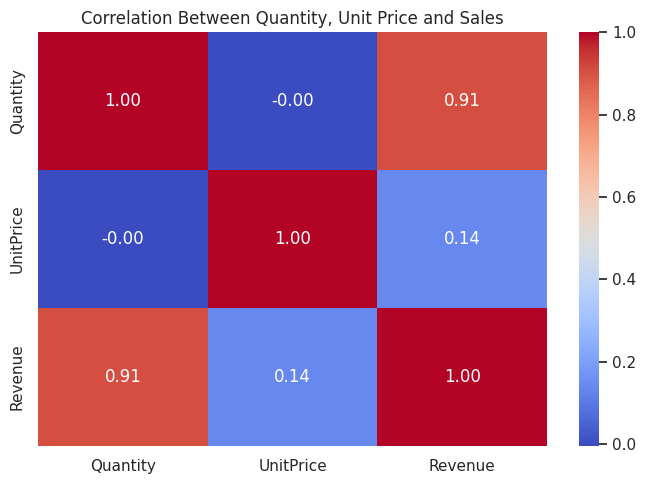

In [46]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "Revenue"
]

correlation = clean_df[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Quantity, Unit Price and Sales")
plt.tight_layout()
plt.show()

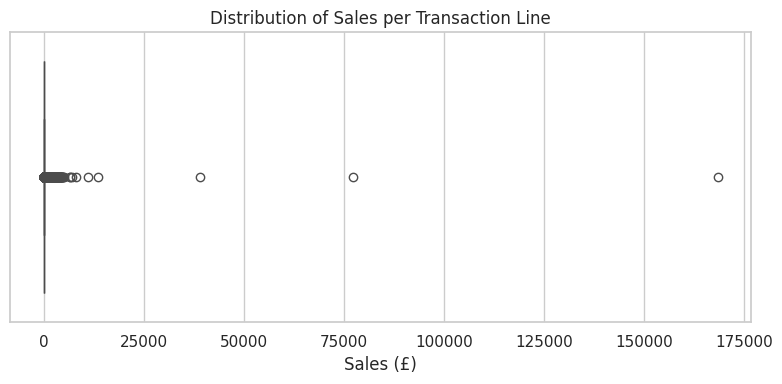

In [47]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=clean_df["Revenue"])

plt.title("Distribution of Sales per Transaction Line")
plt.xlabel("Sales (£)")
plt.tight_layout()
plt.show()

In [48]:
import os

os.makedirs("visualizations", exist_ok=True)

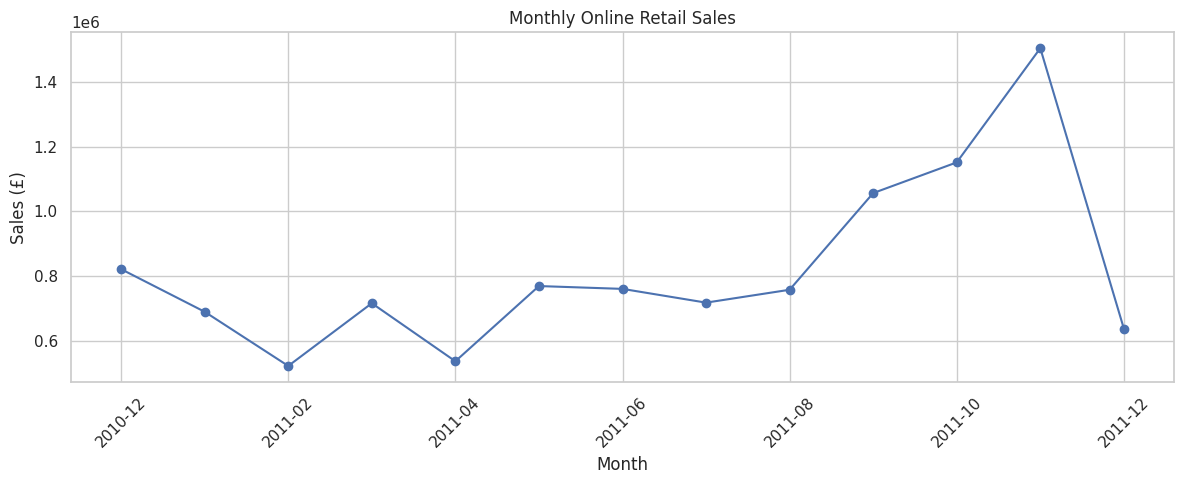

In [49]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Online Retail Sales")
plt.xlabel("Month")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "visualizations/monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

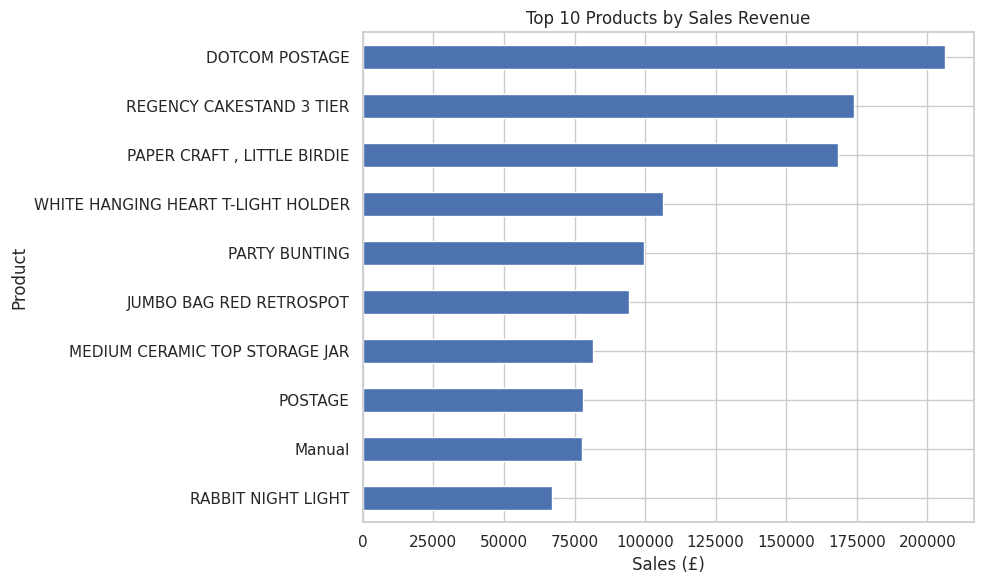

In [51]:
top_products_sales = (
    clean_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_products_sales.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Sales (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.savefig("visualizations/top_products.png", dpi=300)
plt.show()

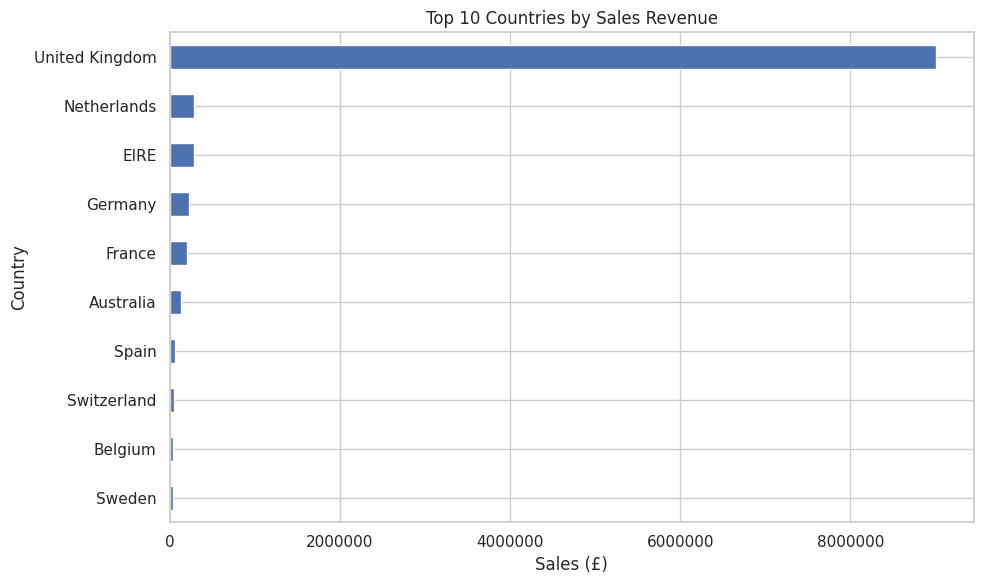

In [55]:
top_countries = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Sales (£)")
plt.ylabel("Country")
plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.savefig("visualizations/country_sales.png", dpi=300)
plt.show()